Section 1 - Data Loading & Exploration (Q1 - Q6)

--- Q1: Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  27 non-null     float64
 1   Salary           28 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


--- Q2: Last 5 rows ---
    YearsExperience    Salary
25              9.0  105582.0
26              NaN  116969.0
27              9.6  112635.0
28             10.3  122391.0
29             10.5  121872.0 

--- Q3: Missing values before imputation ---
YearsExperience    3
Salary             2
dtype: int64 

Missing values after imputation:
 YearsExperience    0
Salary             0
dtype: int64 



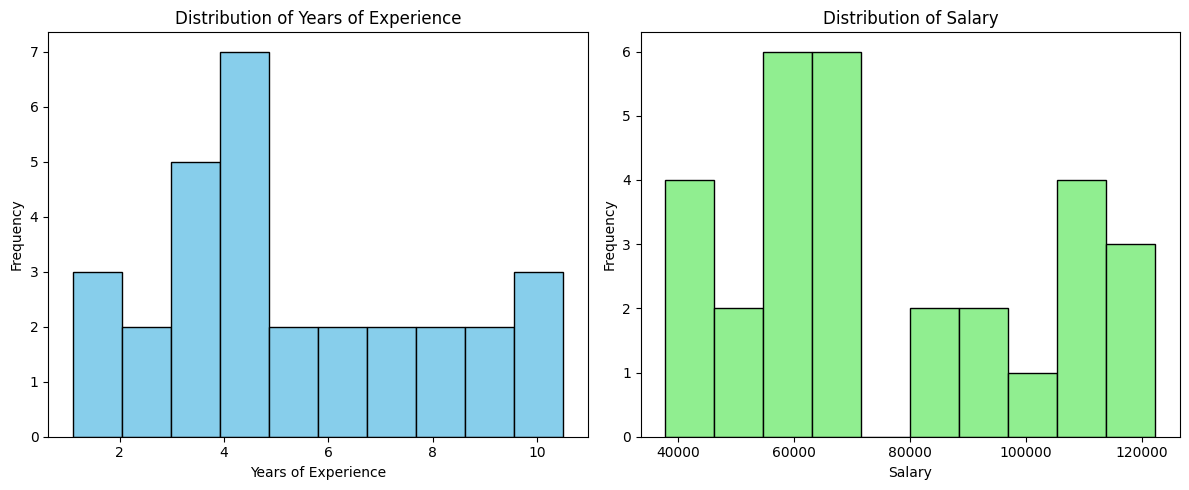

--- Q5: Data Split ---
Training data size: 21 samples
Testing data size: 9 samples



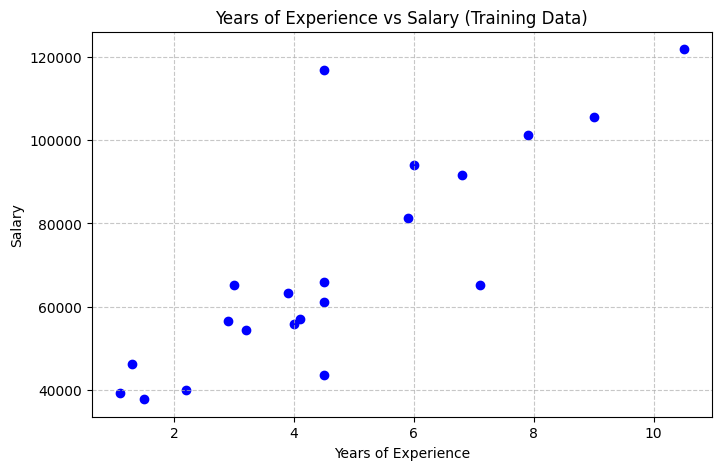

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv('Salary_Data.csv')
print("--- Q1: Dataset Summary ---")
df.info()
print("\n")

print("--- Q2: Last 5 rows ---")
print(df.tail(), "\n")

print("--- Q3: Missing values before imputation ---")
print(df.isnull().sum(), "\n")

df = df.fillna(df.median())
print("Missing values after imputation:\n", df.isnull().sum(), "\n")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['YearsExperience'], bins=10, color='skyblue', edgecolor='black')
plt.title('Distribution of Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(df['Salary'], bins=10, color='lightgreen', edgecolor='black')
plt.title('Distribution of Salary')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

X = df['YearsExperience'].values
y = df['Salary'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("--- Q5: Data Split ---")
print(f"Training data size: {len(X_train)} samples")
print(f"Testing data size: {len(X_test)} samples\n")

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', marker='o')
plt.title('Years of Experience vs Salary (Training Data)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Section 1 - Simple Linear Regression From Scratch (Q7 - Q9)

In [ ]:
mean_x = np.mean(X_train)
mean_y = np.mean(y_train)

numerator = np.sum((X_train - mean_x) * (y_train - mean_y))
denominator = np.sum((X_train - mean_x) ** 2)

m_scratch = numerator / denominator
c_scratch = mean_y - (m_scratch * mean_x)

print("--- Q7: Custom Model Training ---")
print(f"Calculated Slope (m): {m_scratch}")
print(f"Calculated Intercept (c): {c_scratch}\n")

y_pred_scratch = (m_scratch * X_test) + c_scratch
print("--- Q8: Predictions (Custom Model) ---")
print("Actual Salaries:    ", y_test[:5])
print("Predicted Salaries: ", np.round(y_pred_scratch[:5], 2), "\n")

mae_scratch = np.mean(np.abs(y_test - y_pred_scratch))
rmse_scratch = np.sqrt(np.mean((y_test - y_pred_scratch) ** 2))

print("--- Q9: Custom Model Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae_scratch:.2f}")
print(f"Root Mean Square Error (RMSE): {rmse_scratch:.2f}")

--- Q7: Custom Model Training ---
Calculated Slope (m): 8522.035763411277
Calculated Intercept (c): 29794.60385144429

--- Q8: Predictions (Custom Model) ---
Actual Salaries:     [112635.  67938. 113812.  83088.  64445.]
Predicted Salaries:  [111606.15  71552.58  99675.3   74961.39  57065.12] 

--- Q9: Custom Model Evaluation ---
Mean Absolute Error (MAE): 6184.85
Root Mean Square Error (RMSE): 7094.40


Section 2 - Linear Regression Using Inbuilt Function (Q1 - Q4)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_train_reshaped = X_train.reshape(-1, 1)
X_test_reshaped = X_test.reshape(-1, 1)

inbuilt_model = LinearRegression()
inbuilt_model.fit(X_train_reshaped, y_train)

y_pred_inbuilt = inbuilt_model.predict(X_test_reshaped)

mae_inbuilt = mean_absolute_error(y_test, y_pred_inbuilt)
rmse_inbuilt = np.sqrt(mean_squared_error(y_test, y_pred_inbuilt))

print("--- Q4: Model Comparison ---")
print("Custom Model Results:")
print(f"  Slope: {m_scratch:.4f}, Intercept: {c_scratch:.4f}")
print(f"  MAE: {mae_scratch:.2f}")
print(f"  RMSE: {rmse_scratch:.2f}\n")

print("Inbuilt Model Results:")
print(f"  Slope: {inbuilt_model.coef_[0]:.4f}, Intercept: {inbuilt_model.intercept_:.4f}")
print(f"  MAE: {mae_inbuilt:.2f}")
print(f"  RMSE: {rmse_inbuilt:.2f}\n")

print("Conclusion: The results are identical, verifying that our from-scratch math is correct!")

--- Q4: Model Comparison ---
Custom Model Results:
  Slope: 8522.0358, Intercept: 29794.6039
  MAE: 6184.85
  RMSE: 7094.40

Inbuilt Model Results:
  Slope: 8522.0358, Intercept: 29794.6039
  MAE: 6184.85
  RMSE: 7094.40

Conclusion: The results are identical, verifying that our from-scratch math is correct!
